# 单元08：多项式回归、过拟合与正则化

状态：学习中，尚无学生代码执行或模型性能结果。

材料教学案例：ZrB₂含量 → 7085Al复合材料UTS。全部数据均为 **synthetic data（人工模拟数据）**，不是实验结果；生成曲线的峰值不得解释为真实最佳颗粒含量或制备建议。

本Notebook独立于单元07；从头自行编写代码，逐步提交检查后运行。真实报错、首答、提示和修正分别记录。

## 实验约定

- CSV：`data/unit08-materials-polynomial-synthetic.csv`，50行、2列。
- `ZrB2_wt_pct`：按wt.%数值编码，1.5表示1.5 wt.%，不是0.015。
- `UTS_MPa`：模拟目标值，单位MPa。
- 沿用二维列约定：原始X为(m, 1)，y和预测为(m, 1)。模型默认处理截距，不手工添加常数列。
- 在任何拟合和观察曲线之前固定60%/20%/20%划分；两次拆分均用random_state=42，得到30/10/10，后续复用原分组，不换seed挑结果。
- 本轮次数候选预先固定为1、2、12。对12次模型再比较Ridge的alpha：0.01、0.1、1、10、100、1000。
- 流程：PolynomialFeatures(include_bias=False) → StandardScaler → LinearRegression或Ridge。全部置于同一个Pipeline，只对训练数据fit；验证输入和绘图网格直接交给已拟合Pipeline的predict。
- 不对验证集/测试集重新fit任何转换器，不把已经展开或标准化的数据再次传入要求原始输入的完整Pipeline。
- 只用训练/验证数据选择次数和alpha；测试数据不画图、不评分、不参与任何选择，最终锁定一个方案后再评价一次。
- 训练/验证MAE、RMSE只衡量预测误差，不包含参数惩罚；本例二者单位均MPa。
- 所有曲线和指标以实际执行结果为准；十二次不保证一定比二次验证更差，Ridge也不保证一定改善。
- 当前内核名称沿用已安装的`Unit 07 (.venv)`，只是同一Python环境的名称，不代表执行单元07。

## 第1步：读取与预览（当前任务）

自行导入pandas，读取本单元CSV，保存为`data08`，预览前5行。

先发代码检查，再运行并保留真实输出。暂不选择X/y，不划分或拟合模型。

In [2]:
# 由你编写第1步：导入pandas、读取data08、预览前5行。
import pandas as pd
data08 = pd.read_csv("data/unit08-materials-polynomial-synthetic.csv")
data08.head()

,ZrB2_wt_pct,UTS_MPa
0,0.000,467.88
1,0.041,472.25
2,0.082,477.30
3,0.122,483.61
4,0.163,481.89


## 第2步：输入、目标与shape（稍后逐步进行）

识别唯一原始输入与模拟目标，保存为本单元独立变量；按既有二维列约定选列，打印表格、X和y的shape。先预测形状，再检查实际输出。

In [3]:
# 等待前一步完成后，由你编写。
X08 = data08[["ZrB2_wt_pct"]]
y08 = data08[["UTS_MPa"]]
print(data08.shape)
print(X08.shape)
print(y08.shape)

(50, 2)
(50, 1)
(50, 1)


## 第3步：固定训练、验证、测试划分

按实验约定执行两次划分，核对30/10/10及X/y对应关系。保存索引以核对所有候选使用同一分组。此阶段不要拟合转换器，也不要查看测试误差。

In [4]:
# 由你逐步实现固定划分。
from sklearn.model_selection import train_test_split
X08_train,X08_temp,y08_train,y08_temp = train_test_split(X08,y08,test_size = 0.4,random_state = 42)
print(X08_train.shape,X08_temp.shape,y08_train.shape,y08_temp.shape)
X08_val,X08_test,y08_val,y08_test = train_test_split(X08_temp,y08_temp,test_size = 0.5,random_state = 42)
print(X08_val.shape,X08_test.shape,y08_val.shape,y08_test.shape)

(30, 1) (20, 1) (30, 1) (20, 1)
(10, 1) (10, 1) (10, 1) (10, 1)


## 第4步：多项式特征与Pipeline

先理解和检查单输入展开后的列数，随后自行把多项式转换、标准化和线性回归串联。仅训练fit，验证及绘图输入只predict。逐一比较次数1、2、12。

检查：degree=d、include_bias=False时，展开有d列；绘图网格仍从原始二维单列输入完整Pipeline。

In [5]:
# 由你逐步实现，不提前填完整解法。
from sklearn.preprocessing import PolynomialFeatures#创建多项式转换器
poly08_2 = PolynomialFeatures(degree = 2, include_bias = False)#创建二次模型

from sklearn.preprocessing import StandardScaler
scaler08_2 = StandardScaler()#创建标准化器

from sklearn.linear_model import LinearRegression 
reg08_2 = LinearRegression()#创建回归器

from sklearn.pipeline import Pipeline #引入管道：多项式展开，标准化，回归模型("步骤名称", 工具对象)
pipe08_2 = Pipeline([
    ("poly", poly08_2),
    ("scale", scaler08_2),
    ("reg", reg08_2),
])
pipe08_2.fit(X08_train, y08_train)

y08_train_pred_2 = pipe08_2.predict(X08_train)#变量名末尾的 _2 用于标记二次模型，方便之后与其他次数区分
y08_val_pred_2 = pipe08_2.predict(X08_val)
print(y08_train_pred_2.shape
     )
print(y08_val_pred_2.shape
     )

from sklearn.metrics import mean_absolute_error#导入计算MAE的函数
mae08_train_2 = mean_absolute_error(y08_train,y08_train_pred_2)#计算训练集MAE:结果变量 = 函数名称(真实值, 预测值)
print(mae08_train_2)
mae08_val_2 = mean_absolute_error(y08_val,y08_val_pred_2)#计算验证集MAE
print(mae08_val_2)


poly08_1 = PolynomialFeatures(degree = 1, include_bias = False)#创建一次模型

scaler08_1 = StandardScaler()#创建标准化器

reg08_1 = LinearRegression()#创建回归器

pipe08_1 = Pipeline([
    ("poly", poly08_1),
    ("scale", scaler08_1),
    ("reg", reg08_1),
])
pipe08_1.fit(X08_train, y08_train)

y08_train_pred_1 = pipe08_1.predict(X08_train)#变量名末尾的 _2 用于标记二次模型，方便之后与其他次数区分
y08_val_pred_1 = pipe08_1.predict(X08_val)
print(y08_train_pred_1.shape
     )
print(y08_val_pred_1.shape
     )

mae08_train_1 = mean_absolute_error(y08_train,y08_train_pred_1)#计算训练集MAE:结果变量 = 函数名称(真实值, 预测值)
print(mae08_train_1)
mae08_val_1 = mean_absolute_error(y08_val,y08_val_pred_1)#计算验证集MAE
print(mae08_val_1)


poly08_12 = PolynomialFeatures(degree = 12, include_bias = False)#创建十二次多项式特征转换器

scaler08_12 = StandardScaler()#创建标准化器

reg08_12 = LinearRegression()#创建回归器

pipe08_12 = Pipeline([
    ("poly", poly08_12),
    ("scale", scaler08_12),
    ("reg", reg08_12),
])
pipe08_12.fit(X08_train, y08_train)

y08_train_pred_12 = pipe08_12.predict(X08_train)#变量名末尾的 _12 用于标记十二次模型，方便之后与其他次数区分
y08_val_pred_12 = pipe08_12.predict(X08_val)
print(y08_train_pred_12.shape
     )
print(y08_val_pred_12.shape
     )

mae08_train_12 = mean_absolute_error(y08_train,y08_train_pred_12)#计算训练集MAE:结果变量 = 函数名称(真实值, 预测值)
print(mae08_train_12)
mae08_val_12 = mean_absolute_error(y08_val,y08_val_pred_12)#计算验证集MAE
print(mae08_val_12)

(30, 1)
(10, 1)
3.87910920966137
4.278087126458592
(30, 1)
(10, 1)
9.785853805627955
8.219585847395972
(30, 1)
(10, 1)
2.6663586323270865
4.190316693931817


## 第5步：拟合曲线与误差比较

只画训练点、验证点与候选拟合曲线；图题注明synthetic data。横轴ZrB₂含量/wt.%，纵轴模拟UTS/MPa。

记录每个模型的训练与验证MAE/RMSE，解释误差变化。横轴为次数的误差图不是横轴为训练样本数的学习曲线。

(200,)
(200, 1)
(200, 1) (200, 1) (200, 1)


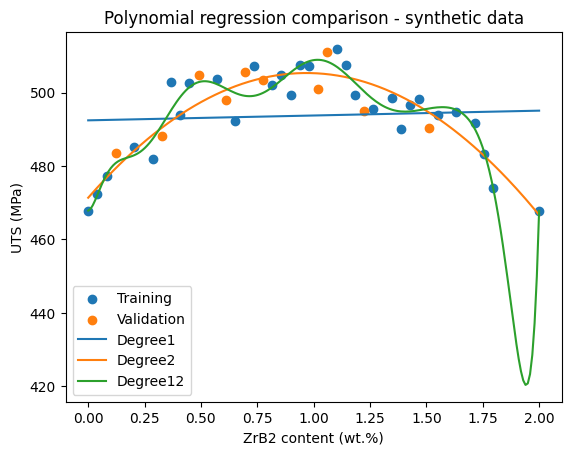

In [6]:
# 待前一步完成后，由你计算和绘图。
import numpy as np
import matplotlib.pyplot as plt
X08_grid = np.linspace(X08_train["ZrB2_wt_pct"].min(), X08_train["ZrB2_wt_pct"].max(), 200) #生成200个等间隔点,np.linspace(起点, 终点, 点数)
X08_plot = pd.DataFrame({"ZrB2_wt_pct": X08_grid}) #保存为单列DataFrame,pd.DataFrame({"列名": 一维数值数组})
print(X08_grid.shape)
print(X08_plot.shape)

#三个已训练的Pipeline预测同一个X08_plot
y08_plot_pred_1 = pipe08_1.predict(X08_plot)
y08_plot_pred_2 = pipe08_2.predict(X08_plot)
y08_plot_pred_12 = pipe08_12.predict(X08_plot)
print(y08_plot_pred_1.shape,y08_plot_pred_2.shape,y08_plot_pred_12.shape)

#散点 → 三条曲线 → 图形标注
#训练集和验证集的样本散点
plt.figure() #创建新图
plt.scatter(X08_train,y08_train,label = "Training")#训练集散点函数
plt.scatter(X08_val,y08_val,label = "Validation")#验证集散点函数

#添加拟合曲线plt.plot(横坐标, 纵坐标, label="图例名称")
plt.plot(X08_plot["ZrB2_wt_pct"], y08_plot_pred_1, label="Degree1") 
plt.plot(X08_plot["ZrB2_wt_pct"], y08_plot_pred_2, label="Degree2") 
plt.plot(X08_plot["ZrB2_wt_pct"], y08_plot_pred_12, label="Degree12") 

#图形标注
plt.xlabel("ZrB2 content (wt.%)") #标注横轴
plt.ylabel("UTS (MPa)") #标注纵轴
plt.title("Polynomial regression comparison - synthetic data") #添加标题
plt.legend() #显示图例
plt.show() #显示图像

## 第6步：Ridge正则化比较

固定12次及同一训练/验证分组，使用预先列出的alpha候选。保持相同特征展开与标准化流程。依据验证误差比较，不能只选训练误差最低者，也不能只比较含不同惩罚的总训练目标。

(30, 1) (10, 1)
5.110107645592669
4.781618618396107
(200, 1)


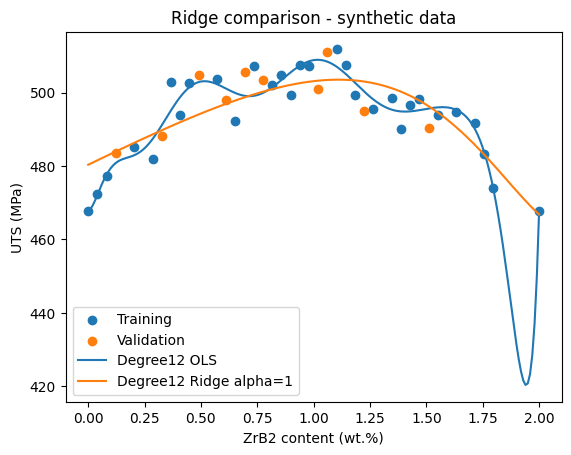

(30, 1) (10, 1)
4.093727746977597
4.146481680127238
(200, 1)


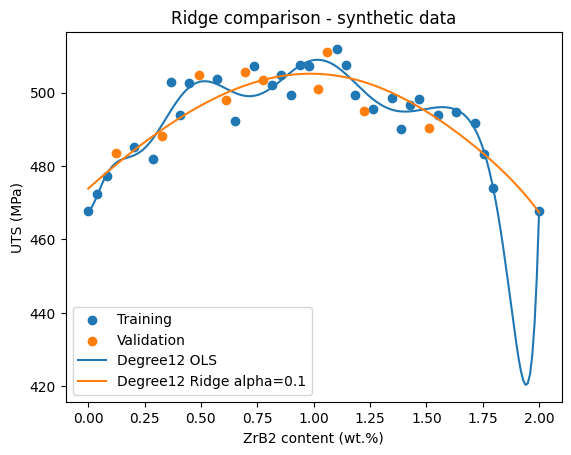

(30, 1)
(10, 1)
3.7427907336170696
4.209376817121404
0.01 3.7427907336170696 4.209376817121404
0.1 4.093727746977597 4.146481680127238
1 5.110107645592669 4.781618618396107
10 6.706553867112996 6.599810058231322
100 8.17530755975614 7.289012030272067
1000 9.375614450668111 7.92572761478454
(30, 1) (10, 1)


In [23]:
# 由你逐步实现Ridge比较。

#alpha = 1时
from sklearn.linear_model import Ridge
ridge08_12_a1 = Ridge(alpha = 1)#新的回归器

poly08_12_a1 = PolynomialFeatures(degree = 12, include_bias = False)#新的多项式转换器

scaler08_12_a1 = StandardScaler()#新的标准化器

pipe08_12_a1 = Pipeline([
    ("poly", poly08_12_a1),
    ("scale", scaler08_12_a1),
    ("reg", ridge08_12_a1),
])#按“多项式展开 → 标准化 → 回归”组装
pipe08_12_a1.fit(X08_train, y08_train)

#Ridge预测
y08_train_pred_12_a1 = pipe08_12_a1.predict(X08_train)
y08_val_pred_12_a1 = pipe08_12_a1.predict(X08_val)
#为保持本单元的二维列约定，下一步只整理已有预测的形状,.reshape(-1, 1),-1 表示自动确定行数，1 表示一列
y08_train_pred_12_a1 = y08_train_pred_12_a1.reshape(-1, 1)
y08_val_pred_12_a1 = y08_val_pred_12_a1.reshape(-1, 1)
print(y08_train_pred_12_a1.shape, y08_val_pred_12_a1.shape)

#计算MAE
mae08_train_12_a1 = mean_absolute_error(y08_train,y08_train_pred_12_a1)#计算训练集MAE:结果变量 = 函数名称(真实值, 预测值)
print(mae08_train_12_a1)
mae08_val_12_a1 = mean_absolute_error(y08_val,y08_val_pred_12_a1)#计算验证集MAE
print(mae08_val_12_a1)

#观察Ridge曲线如何变化
y08_plot_pred_12_a1 = pipe08_12_a1.predict(X08_plot)
y08_plot_pred_12_a1 = y08_plot_pred_12_a1.reshape(-1, 1)
print(y08_plot_pred_12_a1.shape)

plt.figure() #创建新图
plt.scatter(X08_train,y08_train,label = "Training")#训练集散点函数
plt.scatter(X08_val,y08_val,label = "Validation")#验证集散点函数

plt.plot(X08_plot["ZrB2_wt_pct"], y08_plot_pred_12, label="Degree12 OLS") 
plt.plot(X08_plot["ZrB2_wt_pct"], y08_plot_pred_12_a1, label="Degree12 Ridge alpha=1") 

plt.xlabel("ZrB2 content (wt.%)") #标注横轴
plt.ylabel("UTS (MPa)") #标注纵轴
plt.title("Ridge comparison - synthetic data") #添加标题
plt.legend() #显示图例
plt.show() #显示图像




#创建alpha = 0.1的新候选
ridge08_12_a0p1 = Ridge(alpha = 0.1)#新的回归器

poly08_12_a0p1 = PolynomialFeatures(degree = 12, include_bias = False)#新的多项式转换器

scaler08_12_a0p1 = StandardScaler()#新的标准化器

pipe08_12_a0p1 = Pipeline([
    ("poly", poly08_12_a0p1),
    ("scale", scaler08_12_a0p1),
    ("reg", ridge08_12_a0p1),
])#按“多项式展开 → 标准化 → 回归”组装
pipe08_12_a0p1.fit(X08_train, y08_train)

#Ridge预测
y08_train_pred_12_a0p1 = pipe08_12_a0p1.predict(X08_train)
y08_val_pred_12_a0p1 = pipe08_12_a0p1.predict(X08_val)
#为保持本单元的二维列约定，下一步只整理已有预测的形状,.reshape(-1, 1),-1 表示自动确定行数，1 表示一列
y08_train_pred_12_a0p1 = y08_train_pred_12_a0p1.reshape(-1, 1)
y08_val_pred_12_a0p1 = y08_val_pred_12_a0p1.reshape(-1, 1)
print(y08_train_pred_12_a0p1.shape, y08_val_pred_12_a0p1.shape)

#计算MAE
mae08_train_12_a0p1 = mean_absolute_error(y08_train,y08_train_pred_12_a0p1)#计算训练集MAE:结果变量 = 函数名称(真实值, 预测值)
print(mae08_train_12_a0p1)
mae08_val_12_a0p1 = mean_absolute_error(y08_val,y08_val_pred_12_a0p1)#计算验证集MAE
print(mae08_val_12_a0p1)

#观察Ridge曲线如何变化
y08_plot_pred_12_a0p1 = pipe08_12_a0p1.predict(X08_plot)
y08_plot_pred_12_a0p1 = y08_plot_pred_12_a0p1.reshape(-1, 1)
print(y08_plot_pred_12_a0p1.shape)

plt.figure() #创建新图
plt.scatter(X08_train,y08_train,label = "Training")#训练集散点函数
plt.scatter(X08_val,y08_val,label = "Validation")#验证集散点函数

plt.plot(X08_plot["ZrB2_wt_pct"], y08_plot_pred_12, label="Degree12 OLS") 
plt.plot(X08_plot["ZrB2_wt_pct"], y08_plot_pred_12_a0p1, label="Degree12 Ridge alpha=0.1") 

plt.xlabel("ZrB2 content (wt.%)") #标注横轴
plt.ylabel("UTS (MPa)") #标注纵轴
plt.title("Ridge comparison - synthetic data") #添加标题
plt.legend() #显示图例
plt.show() #显示图像




#不同alpha使用同一套建模流程：输入alpha,返回一条新的pipeline
def make_ridge08_pipeline(alpha):
    poly = PolynomialFeatures(degree=12, include_bias=False)
    scaler = StandardScaler()
    ridge = Ridge(alpha=alpha)  #左边是 Ridge 的参数名称，右边是调用函数时传入的值

    pipe = Pipeline([
        ("poly", poly),
        ("scale", scaler),
        ("reg", ridge),
    ])
    return pipe

#训练管道
pipe08_12_a0p01 = make_ridge08_pipeline(0.01)
pipe08_12_a0p01.fit(X08_train,y08_train)

#预测
y08_train_pred_12_a0p01 = pipe08_12_a0p01.predict(X08_train)
y08_val_pred_12_a0p01 = pipe08_12_a0p01.predict(X08_val)
y08_train_pred_12_a0p01 = y08_train_pred_12_a0p01.reshape(-1, 1)
y08_val_pred_12_a0p01 = y08_val_pred_12_a0p01.reshape(-1, 1)
print(y08_train_pred_12_a0p01.shape)
print(y08_val_pred_12_a0p01.shape)

#计算MAE
mae08_train_12_a0p01 = mean_absolute_error(y08_train,y08_train_pred_12_a0p01)#计算训练集MAE:结果变量 = 函数名称(真实值, 预测值)
print(mae08_train_12_a0p01)
mae08_val_12_a0p01 = mean_absolute_error(y08_val,y08_val_pred_12_a0p01)#计算验证集MAE
print(mae08_val_12_a0p01)


#用for循环减少重复代码
alpha_candidates08 = [0.01, 0.1, 1, 10, 100, 1000] #创建列表

for alpha in alpha_candidates08:
    pipe08_candidate = make_ridge08_pipeline(alpha) #创建新管道
    pipe08_candidate.fit(X08_train,y08_train) #训练这条管道
    y08_train_pred_candidate = pipe08_candidate.predict(X08_train)
    y08_val_pred_candidate = pipe08_candidate.predict(X08_val)
    y08_train_pred_candidate = y08_train_pred_candidate.reshape(-1, 1)
    y08_val_pred_candidate = y08_val_pred_candidate.reshape(-1, 1)
    mae08_train_candidate = mean_absolute_error(y08_train,y08_train_pred_candidate)#计算训练集MAE:结果变量 = 函数名称(真实值, 预测值)
    mae08_val_candidate = mean_absolute_error(y08_val,y08_val_pred_candidate)#计算验证集MAE
    print(alpha,mae08_train_candidate, mae08_val_candidate) #用for循环逐个打印这些值


#为选中的alpha = 0.1建立明确的模型对象
pipe08_selected = make_ridge08_pipeline(0.1)
pipe08_selected.fit(X08_train,y08_train)
y08_train_pred_selected = pipe08_selected.predict(X08_train)
y08_val_pred_selected = pipe08_selected.predict(X08_val)
y08_train_pred_selected = y08_train_pred_selected.reshape(-1, 1)
y08_val_pred_selected = y08_val_pred_selected.reshape(-1, 1)
print(y08_train_pred_selected.shape,y08_val_pred_selected.shape)


## 第7步：锁定方案后的一次最终测试

只有次数、是否使用Ridge、alpha和选模指标都已确定，才开启此步骤。写下选择理由，保留该训练集拟合的最终Pipeline；一次性预测保留测试集，报告MAE/RMSE及单位。

不得再根据测试表现改次数、alpha、seed或选择另一模型。若继续探索，原测试表现只能作为本轮记录，不再是新方案的独立评价。

In [8]:
# 尚未开放最终测试；当前不要填写或执行。


## 单元结束时

完成至少3道概念、2道数学理解、2道Python及1道材料迁移评估；保留首次答案、提示层级及真实运行输出。由学生重启内核、顺序运行并保存后再核验，未执行的格不伪造执行编号或输出。

随后更新notes/exercises/mistakes/quizzes、progress和交接；本单元当前尚未完成。